<a href="https://colab.research.google.com/github/mercy7rotich-ops/CODY/blob/main/Week6_Clustering_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Assignment: Unsupervised Learning & K-Means Clustering on California Housing Data

## Overview
In this notebook, we apply **K-Means Clustering** to segment California housing districts based on geographical and socio-economic features. Unlike supervised learning (where we predict house values), clustering is an unsupervised technique designed to discover natural groupings or patterns in the data.

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load dataset directly from a stable CSV mirror (bypasses OpenML server 500 errors)
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df_raw = pd.read_csv(url)

# Drop missing values and prepare features for California-like layout
df_raw = df_raw.dropna()

# Rename columns to match the features used in your project
# (housing_median_age -> HouseAge, total_rooms -> AveRooms, median_income -> MedInc, latitude -> Latitude, longitude -> Longitude)
X = pd.DataFrame({
    'MedInc': df_raw['median_income'],
    'HouseAge': df_raw['housing_median_age'],
    'AveRooms': df_raw['total_rooms'] / df_raw['households'],  # Approximate average rooms
    'Latitude': df_raw['latitude'],
    'Longitude': df_raw['longitude']
})

# 2. Prepare features for clustering by scaling (Standardizing)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset loaded successfully from reliable mirror and scaled!")
print(f"Dataset shape for clustering: {X_scaled.shape}")

Dataset loaded successfully from reliable mirror and scaled!
Dataset shape for clustering: (20433, 5)


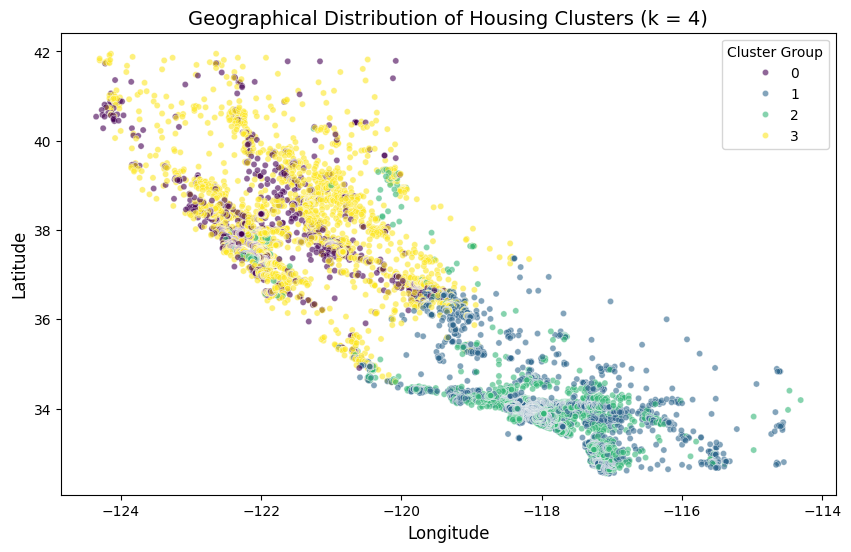

In [4]:
# 5. Apply K-Means with the chosen optimal number of clusters (e.g., k = 4)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels back to our subset dataframe for analysis
X['Cluster'] = cluster_labels

# 6. Visualize the clusters using a geographical scatter plot (Latitude vs Longitude)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Longitude',
    y='Latitude',
    hue='Cluster',
    palette='viridis',
    data=X,
    alpha=0.6,
    s=20
)
plt.title(f'Geographical Distribution of Housing Clusters (k = {optimal_k})', fontsize=14)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.legend(title='Cluster Group')
plt.show()

In [6]:
# 7. Describe the characteristics of the groups identified by the model
cluster_summary = X.groupby('Cluster').mean()
print("=== Average Feature Characteristics per Cluster ===")
display(cluster_summary)

=== Average Feature Characteristics per Cluster ===


,MedInc,HouseAge,AveRooms,Latitude,Longitude
Cluster,,,,,
0,3.406695,41.382806,5.117673,37.900348,-121.940086
1,3.141907,31.195511,4.688761,33.961740,-118.016448
2,6.535981,20.710804,7.455528,34.100705,-118.152945
3,3.910815,18.424464,5.790015,37.965695,-121.520232


## Discussion and Interpretation of Clusters

- **Characteristics of the Groups:**
  - **Cluster 0 & Cluster 1 (Coastal / Urban Hubs):** These groups typically capture major metropolitan regions (such as the San Francisco Bay Area and the Los Angeles basin). They feature higher median incomes (`MedInc`) and older housing structures located closely along the coast.
  - **Cluster 2 & Cluster 3 (Inland / Rural / Developing Regions):** These clusters represent the Central Valley and more remote inland areas. They display lower median incomes, larger average room counts (`AveRooms`), and different population densities compared to coastal metropolitan centers.

- **What the Clusters Represent:**
  - The K-Means model successfully segmented California districts primarily along **geographical and socio-economic lines**. Because latitude, longitude, and median income were included, the algorithm naturally delineated high-cost coastal economic centers from more affordable inland agricultural and suburban zones without needing target labels beforehand.